# Stories Café: Impact of the 2026 Lebanon War

**Question:** how did the war in Lebanon affect sales, customers and behavior?

**Periods compared** (set in the first code cell, so they are easy to change):

| Period | Dates | Why |
|---|---|---|
| Before the war | Jan 1 to Feb 28, 2026 | Baseline |
| War | Mar 1 to Apr 15, 2026 | Fighting began on Mar 2. A US-brokered cessation of hostilities took effect on Apr 16 |
| After the ceasefire | Apr 16 to Jun 30, 2026 | Truce extended several times, though Israeli airstrikes continued |

**Note on the end date:** there is no single clear "end of the war". The Apr 16 cessation of hostilities was temporary and extended several times. Airstrikes continued after it, and a conditional Israel–Lebanon ceasefire was announced on Jun 4. This notebook uses Apr 16 as the end of active war. To test another end date, change `WAR_END` below and re-run.

Sources: [2026 Lebanon war](https://en.wikipedia.org/wiki/2026_Lebanon_war), [2026 Israel–Lebanon ceasefire](https://en.wikipedia.org/wiki/2026_Israel%E2%80%93Lebanon_ceasefire), [Al Jazeera, Jun 4 2026](https://www.aljazeera.com/news/2026/6/4/israel-and-lebanon-agree-to-conditional-ceasefire), [NPR, Jun 4 2026](https://www.npr.org/2026/06/04/g-s1-125942/israel-lebanon-ceasefire)

**Sections**
1. Setup and period definitions
2. Headline comparison (per day, so periods of different length are comparable)
3. Daily orders over time
4. Trend-adjusted effect: did the war push sales below where they were heading?
5. Branches
6. Behavior: time of day, dine-in vs takeaway, product mix
7. Customers
8. Conclusion

## 1. Setup and period definitions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates

# --- Period boundaries: change these to test other definitions ---
WAR_START = pd.Timestamp("2026-03-01")
WAR_END = pd.Timestamp("2026-04-15")   # last day before the Apr 16 cessation of hostilities
PERIODS = ["Before the war", "War", "After the ceasefire"]

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Periods are an ordered sequence, so they use one blue hue from light to dark
PERIOD_COLORS = dict(zip(PERIODS, ["#86b6ef", "#256abf", "#0d366b"]))
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
ACCENT, MUTED, WAR_SHADE = "#2a78d6", "#b9b8b3", "#f3d9d3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour


def period_of(dates):
    return pd.Categorical(np.select([dates < WAR_START, dates <= WAR_END], PERIODS[:2], PERIODS[2]),
                          PERIODS, ordered=True)


df["period"] = period_of(df["Date"])
orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), customer=("Customer ID", "first"),
    revenue=(R, "sum"), profit=(GP, "sum"), items=("Quantity", "sum"), discount=("Discount Rate", "max"),
)
orders["period"] = period_of(orders["date"])
days = orders.groupby("period", observed=True)["date"].nunique()
days.rename("days in period").to_frame()

,days in period
period,
Before the war,59
War,46
After the ceasefire,76


## 2. Headline comparison

In [2]:
summary = orders.groupby("period", observed=True).agg(
    orders=("revenue", "size"), revenue=("revenue", "sum"), profit=("profit", "sum"),
    aov=("revenue", "mean"), items_per_order=("items", "mean"),
    takeaway_share=("order_type", lambda s: (s == "Takeaway").mean()),
    known_customer_share=("customer", lambda s: s.notna().mean()),
    discounted_share=("discount", lambda s: (s > 0).mean()),
)
summary.insert(0, "orders_per_day", summary["orders"] / days)
summary.insert(1, "revenue_per_day", summary["revenue"] / days)
summary.insert(2, "profit_per_day", summary["profit"] / days)
summary["gross_margin"] = summary["profit"] / summary["revenue"]

table = summary[["orders_per_day", "revenue_per_day", "profit_per_day", "aov", "items_per_order",
                 "gross_margin", "takeaway_share", "known_customer_share", "discounted_share"]].T
table["War vs before"] = table["War"] / table["Before the war"] - 1
table["After vs war"] = table["After the ceasefire"] / table["War"] - 1
table.style.format("{:,.2f}").format("{:+.1%}", subset=["War vs before", "After vs war"])

period,Before the war,War,After the ceasefire,War vs before,After vs war
orders_per_day,155.32,185.30,213.14,+19.3%,+15.0%
revenue_per_day,"1,401.99","1,665.41","1,919.17",+18.8%,+15.2%
profit_per_day,821.50,976.30,"1,126.52",+18.8%,+15.4%
aov,9.03,8.99,9.00,-0.4%,+0.2%
items_per_order,1.60,1.60,1.59,+0.1%,-0.5%
gross_margin,0.59,0.59,0.59,+0.0%,+0.1%
takeaway_share,0.41,0.40,0.41,-1.3%,+1.8%
known_customer_share,0.64,0.63,0.64,-0.6%,+0.6%
discounted_share,0.08,0.10,0.10,+20.9%,-4.1%


**Takeaway:** orders and revenue per day were **higher during the war than before it (about +20%)**, and rose again after the ceasefire. Everything that describes *how* people bought stayed the same across all three periods: average order value (about $9.00), items per order, gross margin (59%), takeaway share (about 41%) and share of known customers (about 63%).

The share of discounted orders rose (8% to 10%). That's because the 15% Harbour promo (Mar 12-19) fell inside the war period, not because of the war itself (see `01_eda`, section 11).

A raw before/after comparison can be misleading, though, because sales were already growing every week before the war. Section 4 corrects for that.

## 3. Daily orders over time

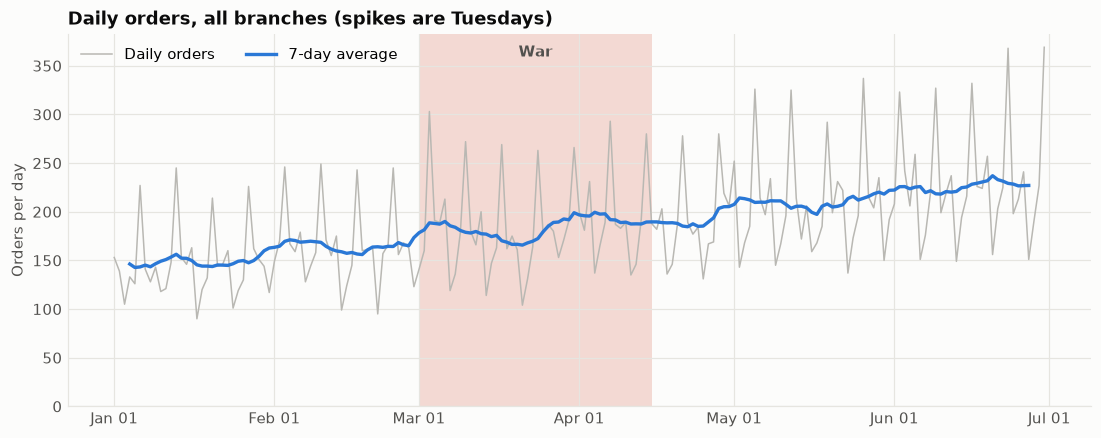

In [3]:
daily = orders.groupby("date").size().rename("orders").to_frame()
daily["rolling_7d"] = daily["orders"].rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.axvspan(WAR_START, WAR_END, color=WAR_SHADE, lw=0, zorder=0)
ax.text(WAR_START + (WAR_END - WAR_START) / 2, 0.97, "War", transform=ax.get_xaxis_transform(),
        ha="center", va="top", color=INK2, fontweight="bold")
ax.plot(daily.index, daily["orders"], color=MUTED, lw=1, label="Daily orders")
ax.plot(daily.index, daily["rolling_7d"], color=ACCENT, lw=2.2, label="7-day average")
ax.set_ylim(0)
ax.set_ylabel("Orders per day")
ax.set_title("Daily orders, all branches (spikes are Tuesdays)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="upper left", ncols=2)
plt.show()

## 4. Trend-adjusted effect

Sales were already growing week after week in January and February. To ask whether the war **pushed sales below where they were heading**, we:
1. fit a simple model on **pre-war days only**: daily orders = growth trend + weekday effect (this captures the Tuesday spike and weak weekends);
2. project that model forward to get the **expected** orders if the pre-war pattern had simply continued;
3. compare **actual vs expected** in each period.

If the war hurt the business, actual orders during the war should fall clearly below the expected line.

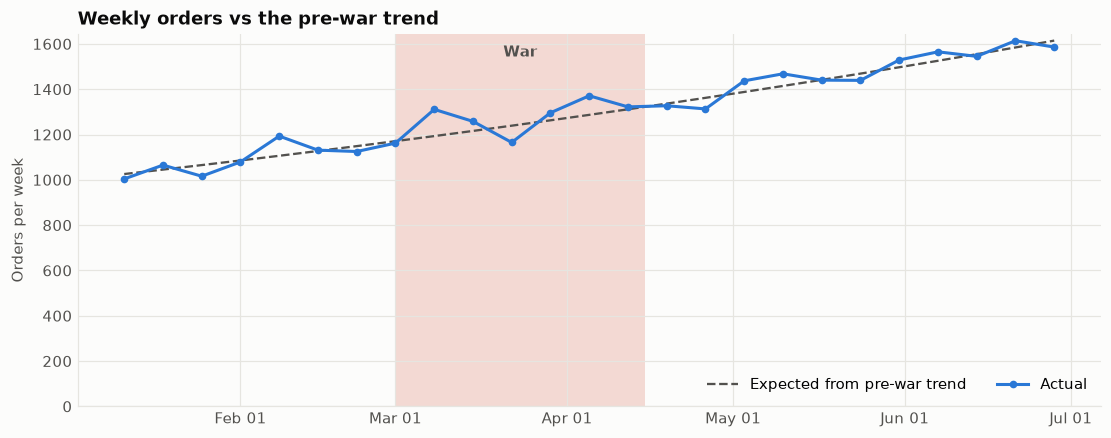

,orders,expected,actual vs expected
period,,,
Before the war,"9,164","9,141",+0.3%
War,"8,524","8,311",+2.6%
After the ceasefire,"16,199","16,104",+0.6%


In [4]:
def fit_expected(daily_orders):
    """Fit log(orders) = trend + weekday on pre-war days; return expected orders for every day."""
    t = (daily_orders.index - daily_orders.index[0]).days.to_numpy()
    dow = pd.get_dummies(daily_orders.index.dayofweek, drop_first=True).to_numpy(float)
    X = np.column_stack([np.ones(len(t)), t, dow])
    pre = daily_orders.index < WAR_START
    beta, *_ = np.linalg.lstsq(X[pre], np.log(daily_orders.to_numpy()[pre]), rcond=None)
    return pd.Series(np.exp(X @ beta), index=daily_orders.index)


daily["expected"] = fit_expected(daily["orders"])
daily["period"] = period_of(daily.index)
weekly = daily[["orders", "expected"]].resample("W-SUN").sum().iloc[1:-1]  # full weeks only

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.axvspan(WAR_START, WAR_END, color=WAR_SHADE, lw=0, zorder=0)
ax.text(WAR_START + (WAR_END - WAR_START) / 2, 0.97, "War", transform=ax.get_xaxis_transform(),
        ha="center", va="top", color=INK2, fontweight="bold")
ax.plot(weekly.index, weekly["expected"], color=INK2, lw=1.5, ls="--", label="Expected from pre-war trend")
ax.plot(weekly.index, weekly["orders"], color=ACCENT, marker="o", ms=4, label="Actual")
ax.set_ylim(0)
ax.set_ylabel("Orders per week")
ax.set_title("Weekly orders vs the pre-war trend")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="lower right", ncols=2)
plt.show()

effect = daily.groupby("period", observed=True)[["orders", "expected"]].sum()
effect["actual vs expected"] = effect["orders"] / effect["expected"] - 1
effect.style.format({"orders": "{:,.0f}", "expected": "{:,.0f}", "actual vs expected": "{:+.1%}"})

In [5]:
# Same test for each branch
rows = {}
for b in BRANCHES:
    s = orders[orders["branch"] == b].groupby("date").size()
    e = fit_expected(s)
    p = period_of(s.index)
    rows[b] = (s.groupby(p, observed=True).sum() / e.groupby(p, observed=True).sum() - 1)
pd.DataFrame(rows).T.style.format("{:+.1%}").set_caption("Actual vs expected orders, by branch")

,Before the war,War,After the ceasefire
Harbour,+0.6%,+4.5%,+5.7%
Garden,+0.9%,-2.0%,-6.7%
Uptown,+1.7%,+8.7%,+2.8%


**Takeaway:** across all branches, actual orders during the war were **about 3% above** what the pre-war trend predicted, not below. After the ceasefire they stayed on trend. Overall, the data shows **no negative war effect** on demand.

**By branch:** Harbour (+4.5%) and Uptown (+8.7%) ran above their trends during the war. **Garden was the only branch slightly below its trend (-2%)**, and it fell further behind *after* the ceasefire (-7%). Because Garden's gap grew after the fighting paused, it looks more like Garden's own growth slowing than a war effect. Single-branch models are also noisier, so treat this as a flag to look into, not a conclusion.

## 5. Branches

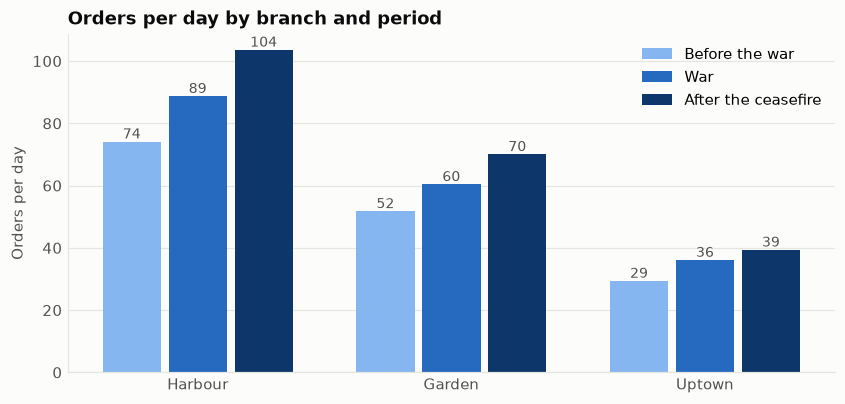

period,Before the war,War,After the ceasefire,War vs before,After vs war
branch,,,,,
Harbour,74.2,88.7,103.6,+19.7%,+16.8%
Garden,51.8,60.5,70.1,+16.8%,+16.0%
Uptown,29.4,36.1,39.4,+22.8%,+9.1%


In [6]:
br = orders.groupby(["period", "branch"], observed=True).size().unstack()[BRANCHES].div(days, axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(BRANCHES))
w = 0.26
for i, p in enumerate(PERIODS):
    vals = br.loc[p].values
    ax.bar(x + (i - 1) * w, vals, width=w - 0.03, color=PERIOD_COLORS[p], label=p)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + 1, f"{v:.0f}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, BRANCHES)
ax.set_ylabel("Orders per day")
ax.set_title("Orders per day by branch and period")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

(br.T.assign(**{"War vs before": lambda t: t["War"] / t["Before the war"] - 1,
                "After vs war": lambda t: t["After the ceasefire"] / t["War"] - 1})
   .style.format("{:.1f}").format("{:+.1%}", subset=["War vs before", "After vs war"]))

**Takeaway:** all three branches grew during the war (Harbour +20%, Garden +17%, Uptown +23% orders per day). None shrank, which is what you might expect if one location were closer to affected areas or if customers moved away. Garden grew the least, consistent with section 4.

## 6. Behavior: time of day, dine-in vs takeaway, product mix

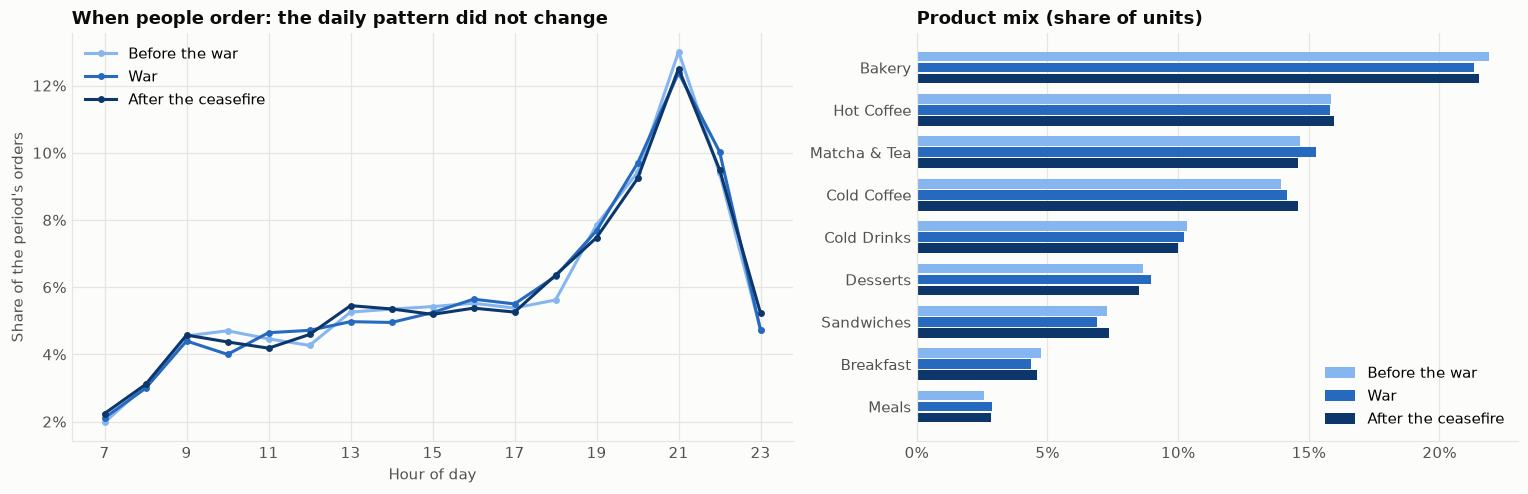

,evening share (18:00+),takeaway share
period,,
Before the war,50.0%,40.9%
War,50.8%,40.4%
After the ceasefire,50.3%,41.1%


In [7]:
hour_mix = pd.crosstab(orders["hour"], orders["period"], normalize="columns")[PERIODS]
type_mix = pd.crosstab(orders["period"], orders["order_type"], normalize="index")
cat_mix = pd.crosstab(df["Category"], df["period"], values=df["Quantity"], aggfunc="sum", normalize="columns")[PERIODS]
cat_mix = cat_mix.sort_values("Before the war")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
for p in PERIODS:
    ax.plot(hour_mix.index, hour_mix[p], color=PERIOD_COLORS[p], marker="o", ms=3.5, label=p)
ax.yaxis.set_major_formatter(pct)
ax.set_xticks(hour_mix.index[::2])
ax.set_xlabel("Hour of day")
ax.set_ylabel("Share of the period's orders")
ax.set_title("When people order: the daily pattern did not change")
ax.legend(loc="upper left")

ax = axes[1]
y = np.arange(len(cat_mix))
h = 0.26
for i, p in enumerate(PERIODS):
    ax.barh(y + (1 - i) * h, cat_mix[p], height=h - 0.03, color=PERIOD_COLORS[p], label=p)  # earliest period on top
ax.set_yticks(y, cat_mix.index)
ax.xaxis.set_major_formatter(pct)
ax.set_title("Product mix (share of units)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

evening = orders.assign(evening=orders["hour"] >= 18).groupby("period", observed=True)["evening"].mean()
pd.DataFrame({"evening share (18:00+)": evening, "takeaway share": type_mix["Takeaway"]}).style.format("{:.1%}")

**Takeaway:** none of the behavior that a war would typically change moved:
- **Evening share stayed the same.** Fear or curfews would usually push visits earlier, but the 21:00 peak held.
- **Takeaway share stayed at about 41%.** People staying home more would usually push this up.
- **Product mix stayed the same.** No shift toward cheaper items, and average order value stayed flat.

## 7. Customers

In [8]:
known = orders.dropna(subset=["customer"])
first_visit = known.groupby("customer")["date"].min()
known = known.assign(first_visit=known["customer"].map(first_visit))

cust = known.groupby("period", observed=True).agg(active_customers=("customer", "nunique"),
                                                  orders=("revenue", "size"))
cust["new_customers"] = first_visit.groupby(period_of(first_visit), observed=True).size()
cust["active_per_week"] = cust["active_customers"] / (days / 7)
cust["orders_per_active_customer_per_week"] = cust["orders"] / cust["active_customers"] / (days / 7)
cust["new_customers_per_week"] = cust["new_customers"] / (days / 7)
cust[["active_customers", "new_customers_per_week", "orders_per_active_customer_per_week"]].style.format(
    {"active_customers": "{:,.0f}", "new_customers_per_week": "{:.1f}", "orders_per_active_customer_per_week": "{:.2f}"})

,active_customers,new_customers_per_week,orders_per_active_customer_per_week
period,,,
Before the war,"2,822",334.8,0.25
War,"2,762",82.0,0.30
After the ceasefire,"3,320",12.2,0.29


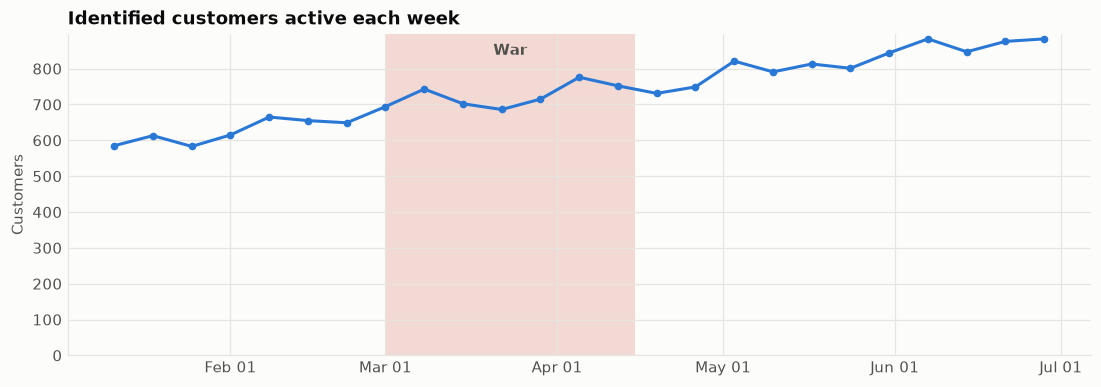

In [9]:
weekly_active = known.set_index("date").resample("W-SUN")["customer"].nunique().iloc[1:-1]

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axvspan(WAR_START, WAR_END, color=WAR_SHADE, lw=0, zorder=0)
ax.text(WAR_START + (WAR_END - WAR_START) / 2, 0.97, "War", transform=ax.get_xaxis_transform(),
        ha="center", va="top", color=INK2, fontweight="bold")
ax.plot(weekly_active.index, weekly_active.values, color=ACCENT, marker="o", ms=4)
ax.set_ylim(0)
ax.set_ylabel("Customers")
ax.set_title("Identified customers active each week")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.show()

**Takeaway:** the number of identified customers visiting each week kept climbing through the war. Existing customers did not drop off. New sign-ups were already falling before the war (see `01_eda`) and kept falling at the same pace, so the war doesn't explain that decline either.

## 8. Conclusion

**The data shows no measurable effect of the war on the business.**

| What we checked | Before → War → After | War effect? |
|---|---|---|
| Orders per day | Grew steadily | None. About 3% *above* the pre-war trend |
| Average order value | Flat at about $9.00 | None |
| Gross margin, prices, costs | Unchanged | None |
| Time of day (evening peak) | Unchanged | None |
| Takeaway share | About 41% throughout | None |
| Product mix | Unchanged | None |
| Branches | All grew | None overall. Garden slightly below its trend (-2%), but the gap widened after the ceasefire, so it's likely unrelated |
| Active customers | Kept rising | None |

**How to interpret this:**
1. **The dataset is synthetic** (IDs start with `SYN-`). It was almost certainly generated with a smooth growth trend and no war shock built in. Whatever this shows, it doesn't tell us how a real café in Lebanon was affected.
2. **If the team wants to use the war in the pitch**, frame it as *resilience*: "sales kept growing through the war and the ceasefire". Don't claim a war impact the data doesn't show.
3. **What real data would usually show** in a conflict, for comparison: a drop in evening and dine-in visits, a shift toward takeaway or delivery, lower spend per order, rising costs from supply disruption, and differences between branches depending on location. None of these appear here.

To test a different end date (for example the Jun 4 conditional ceasefire), change `WAR_END` in the first code cell and re-run all cells.